# Ridge regression sales prediction

This notebook fits a separate Ridge regression model for each supplied sales target using the month's known features. Dates are validated and retained for plotting; no lagging, interpolation, or imputation is performed. Standardized-feature coefficients describe model associations rather than causal importance.

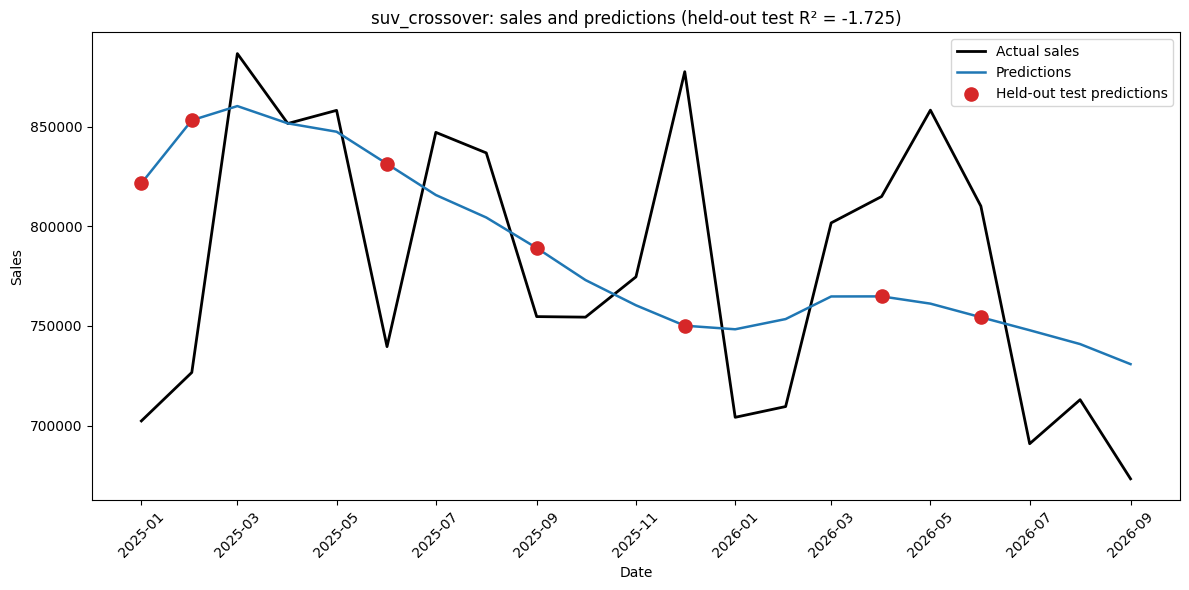

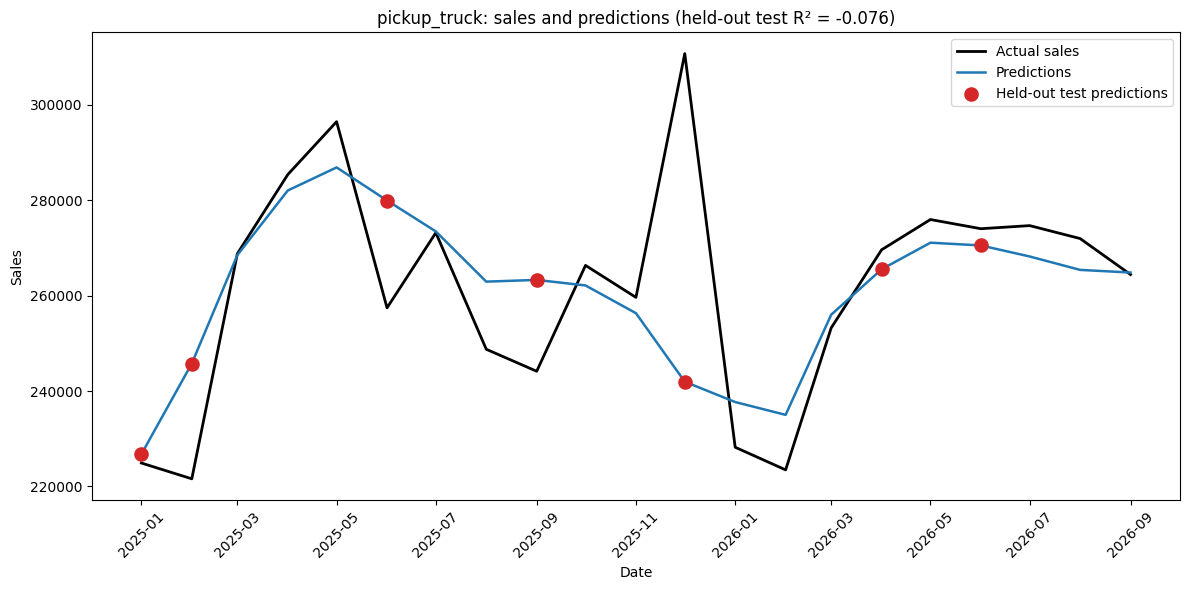

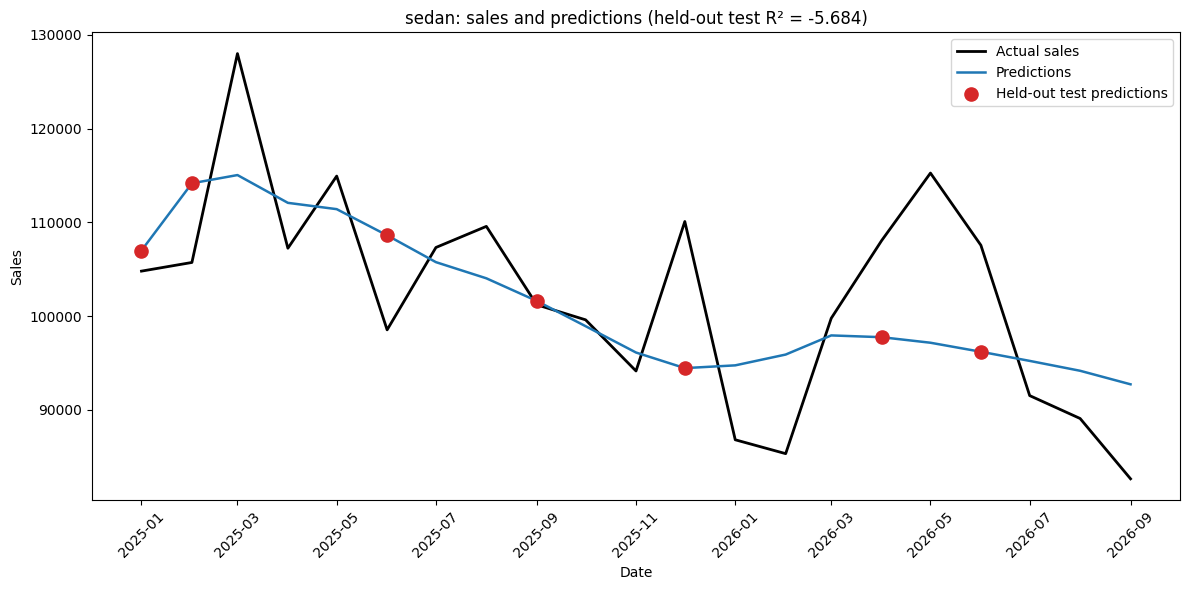

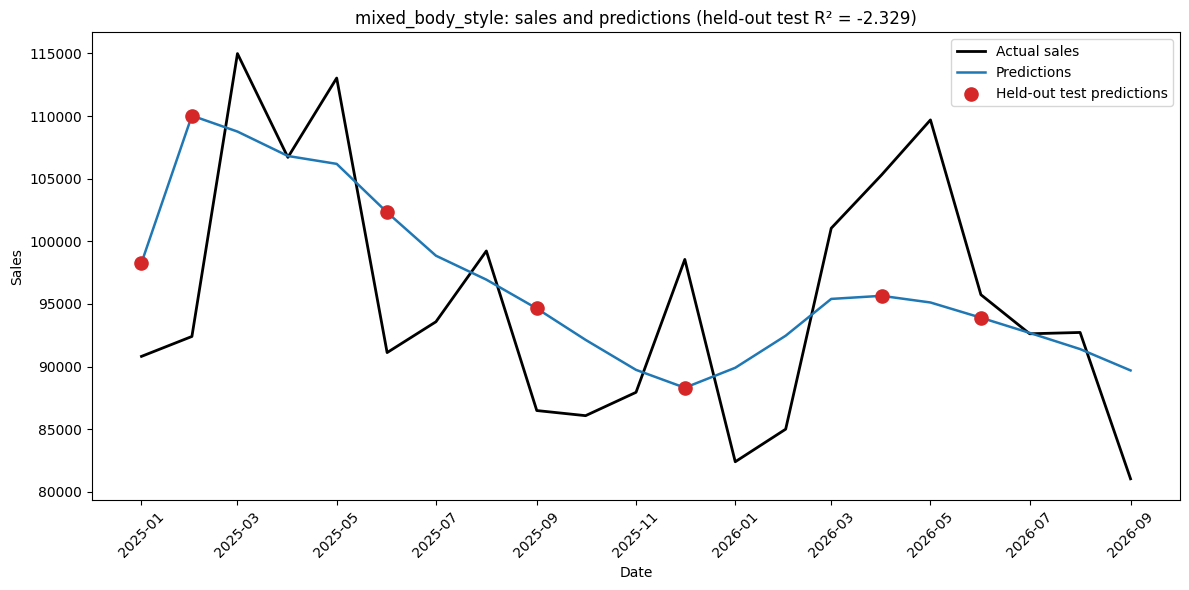

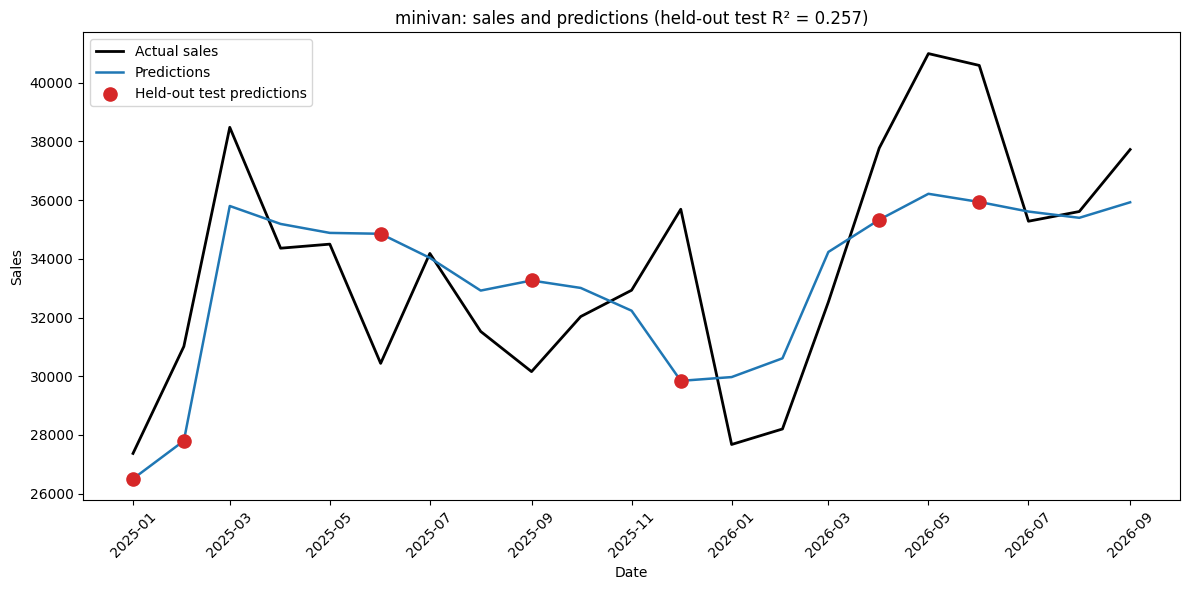

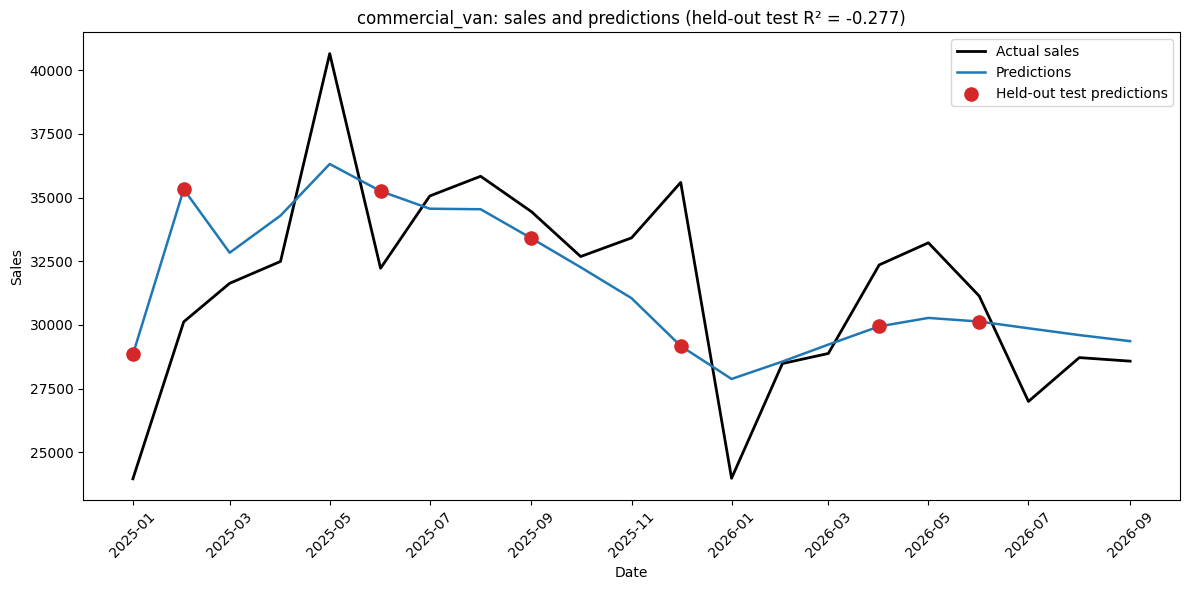

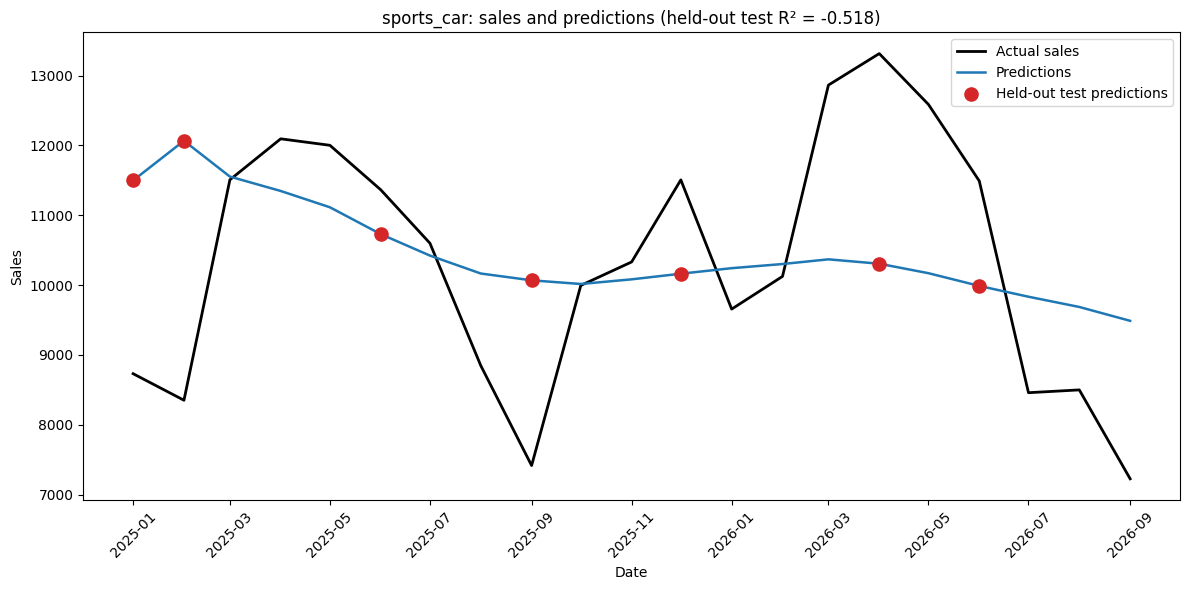

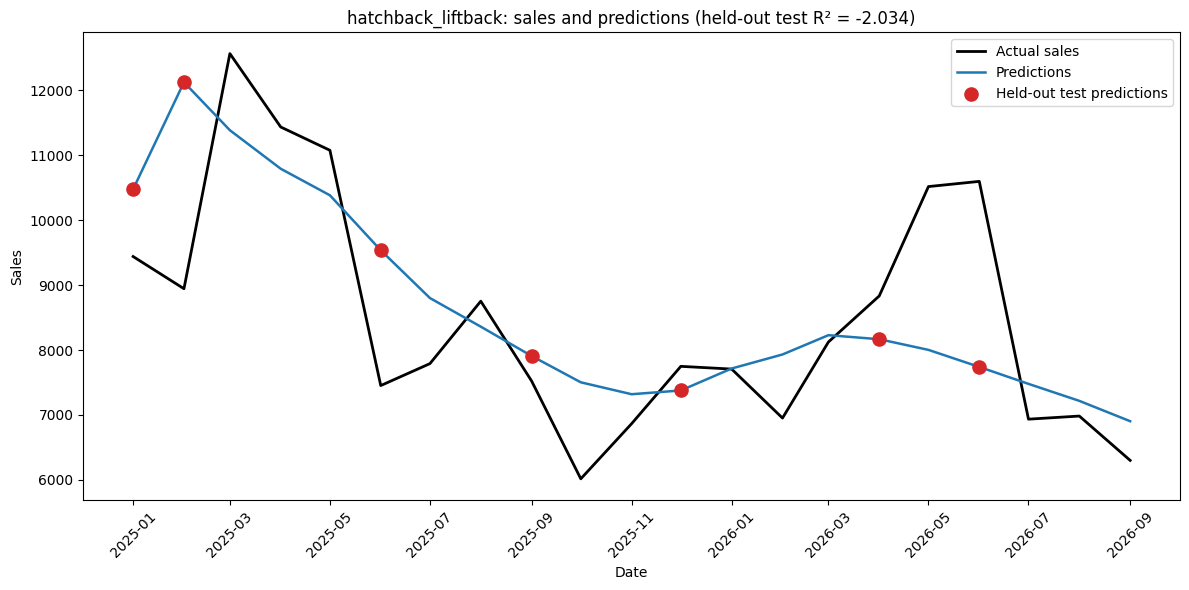

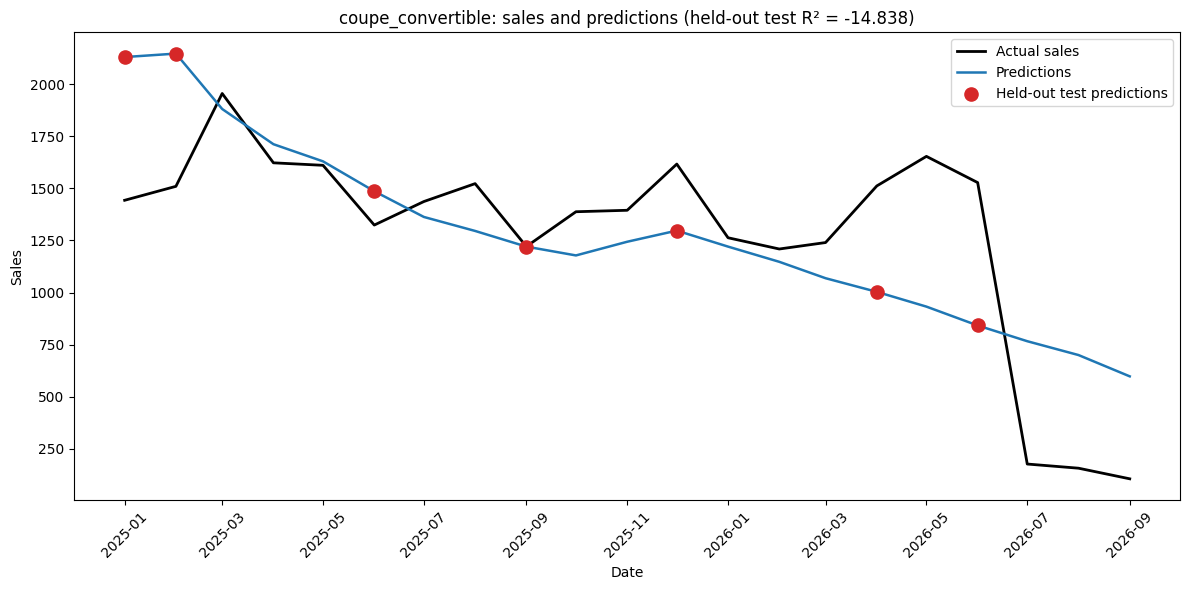

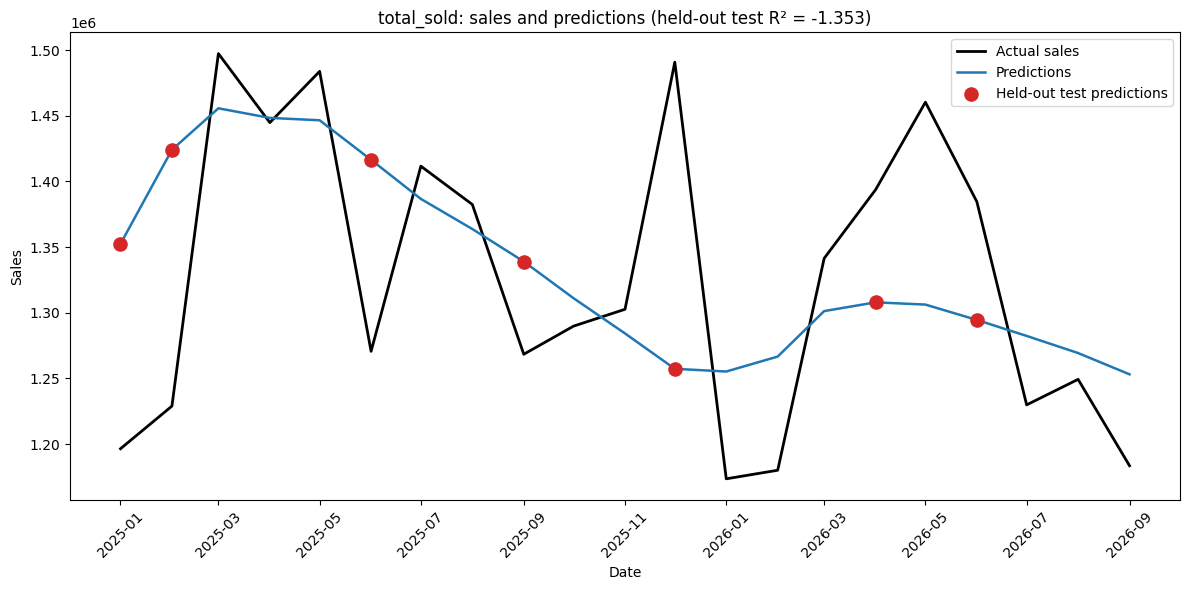

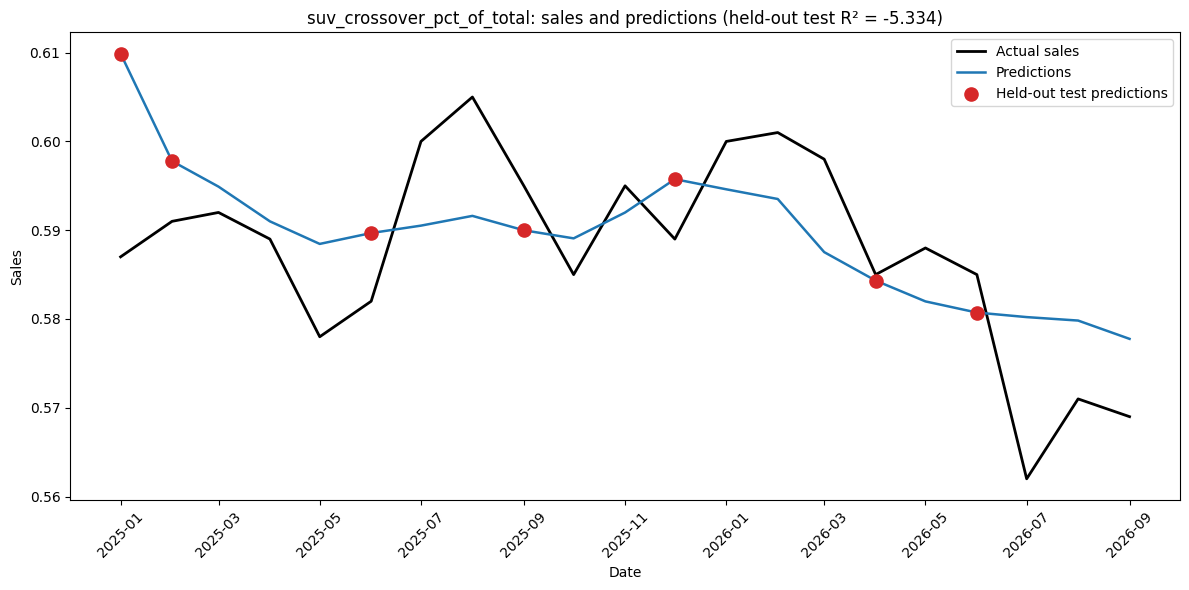

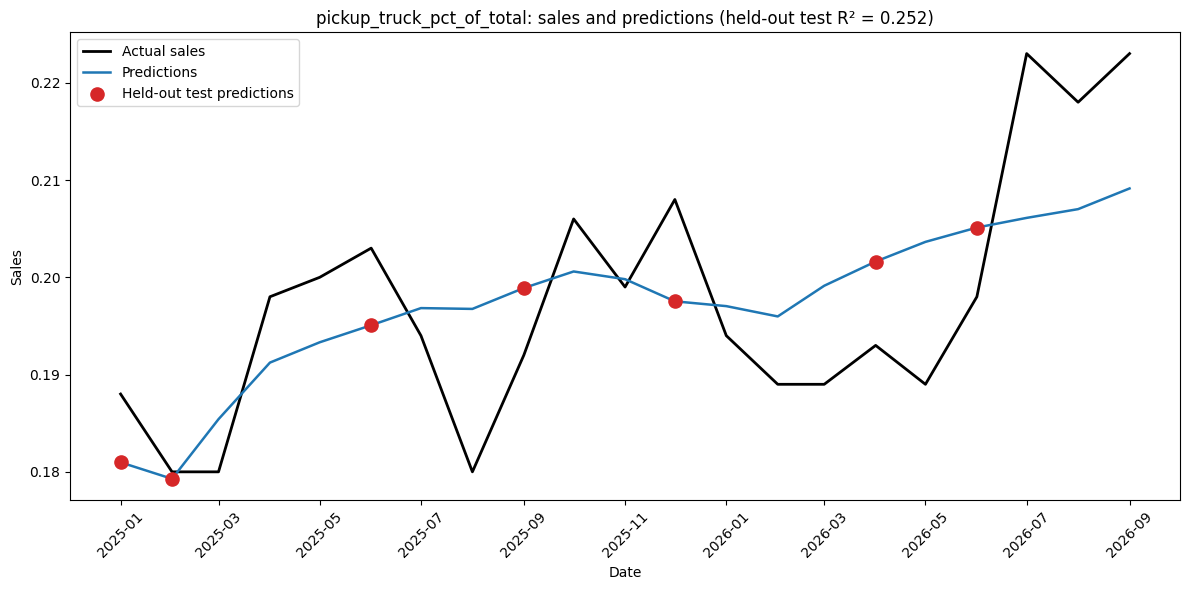

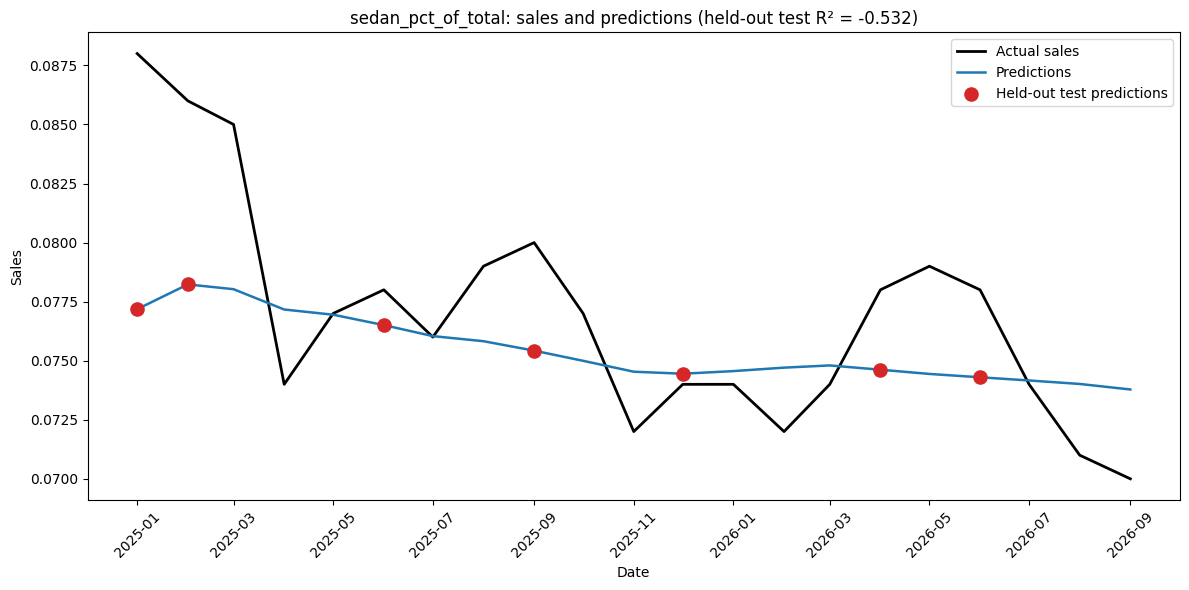

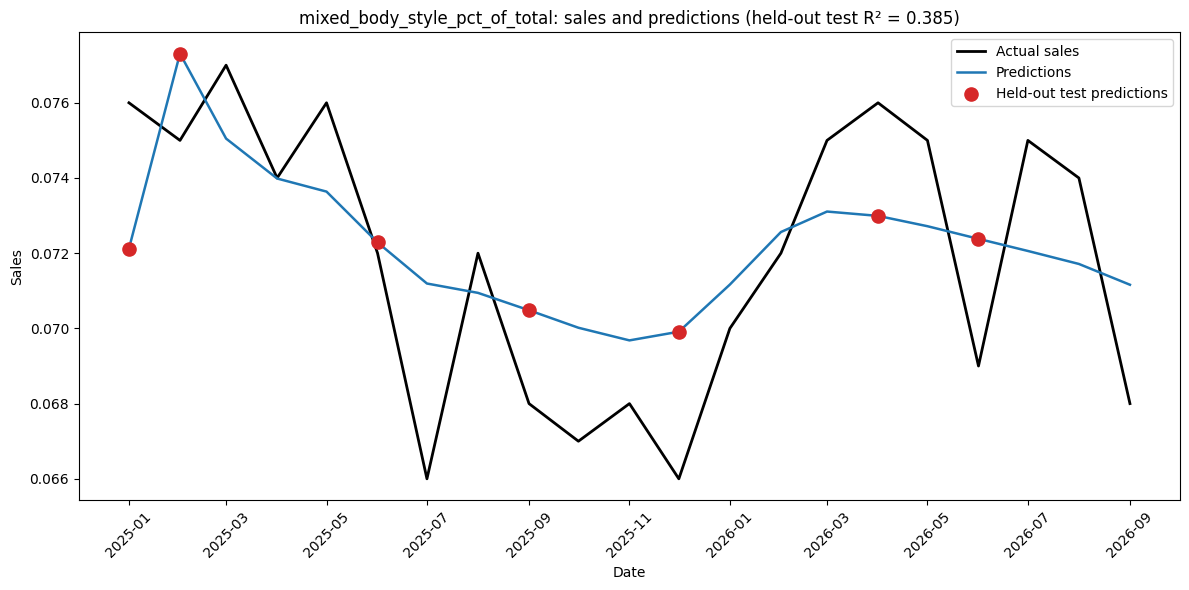

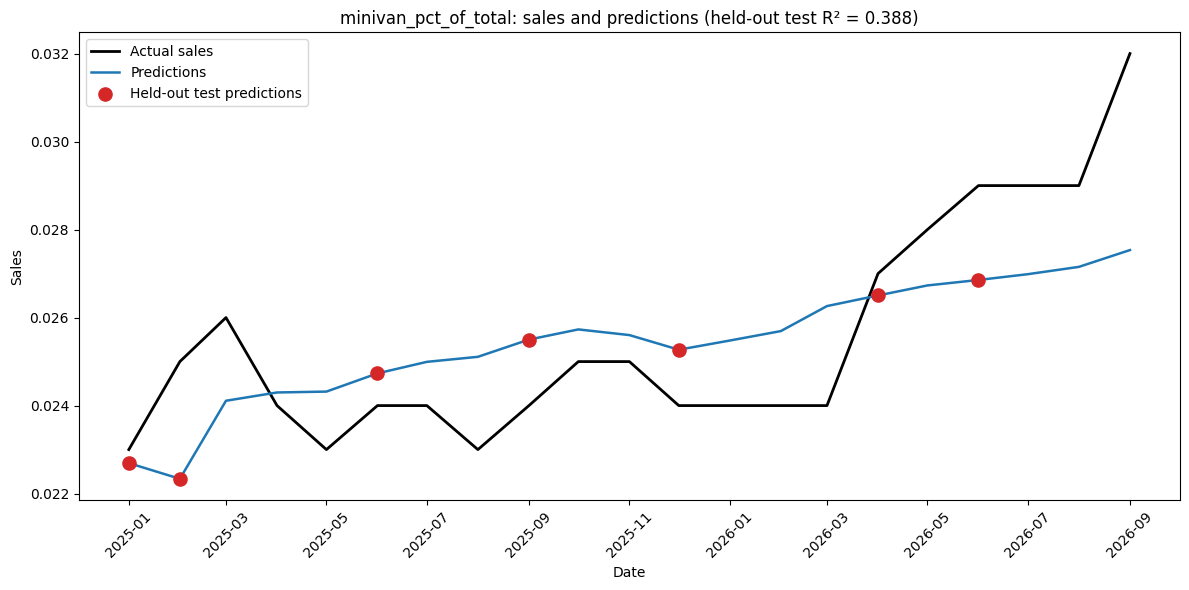

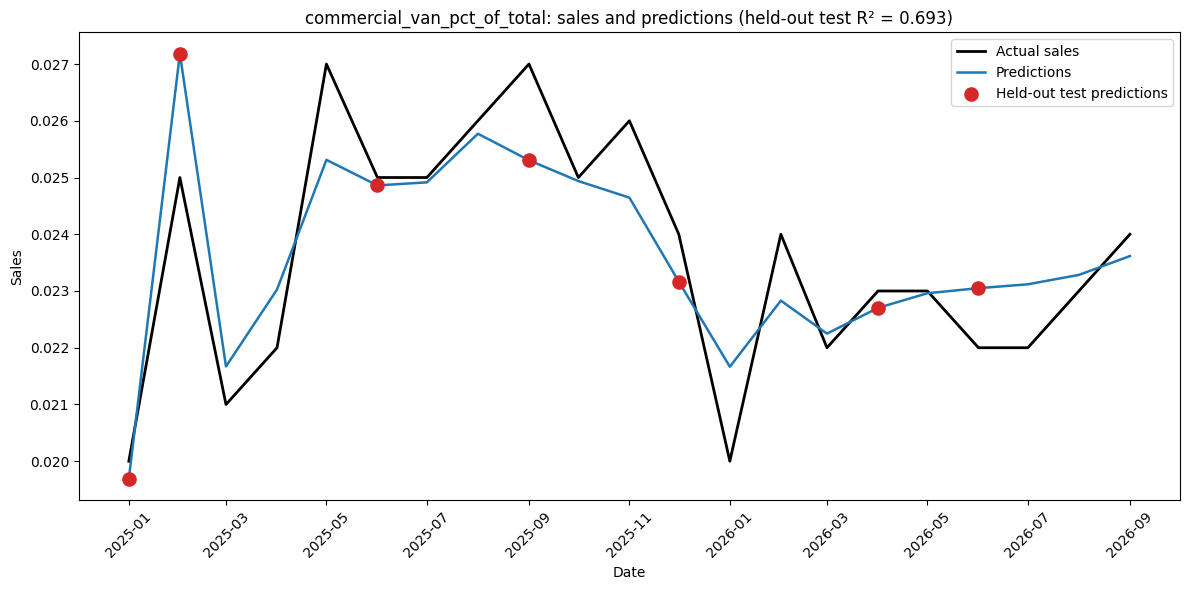

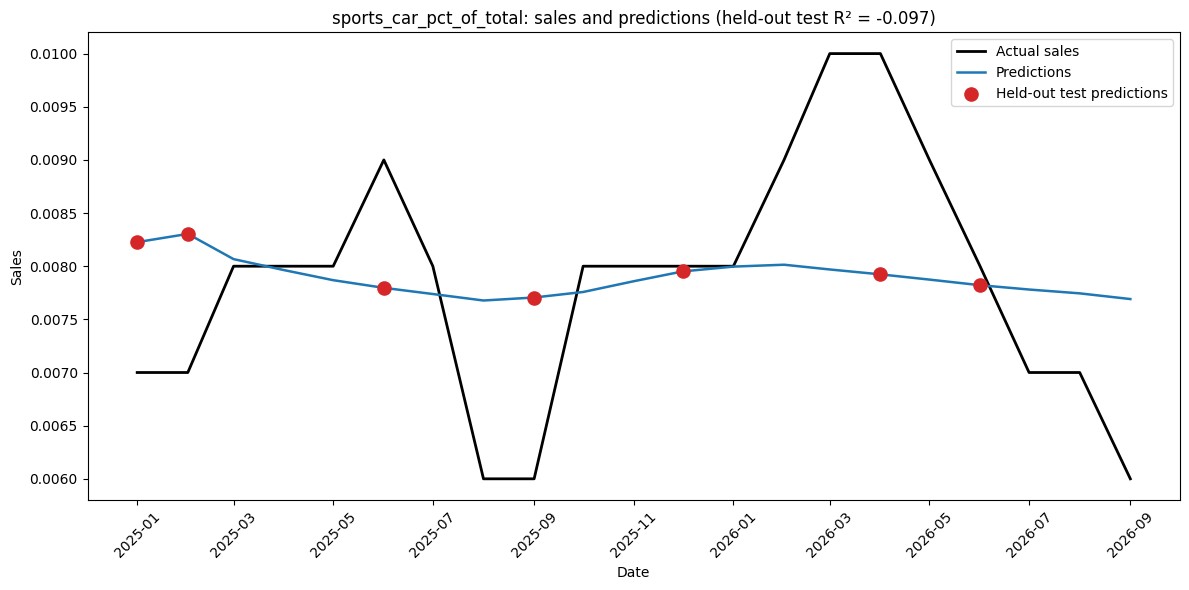

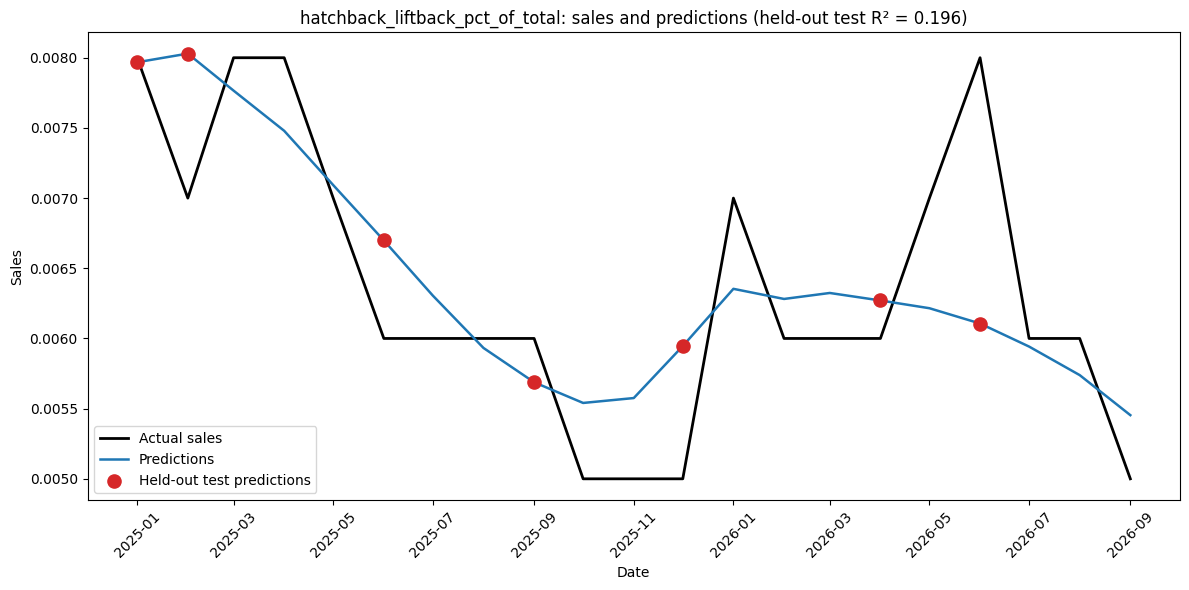

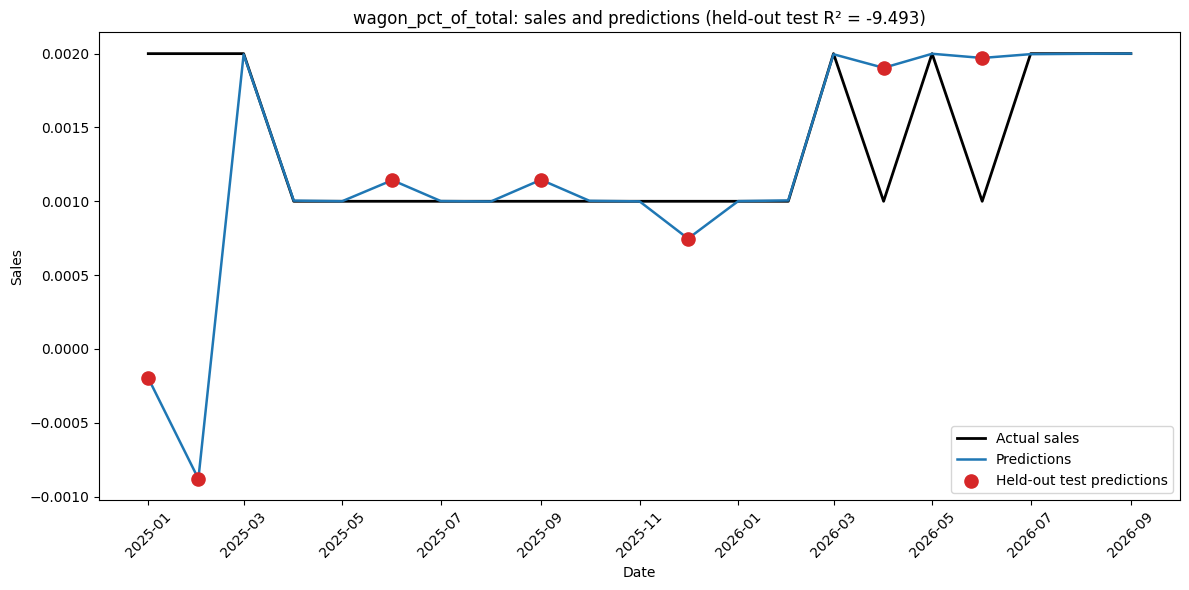

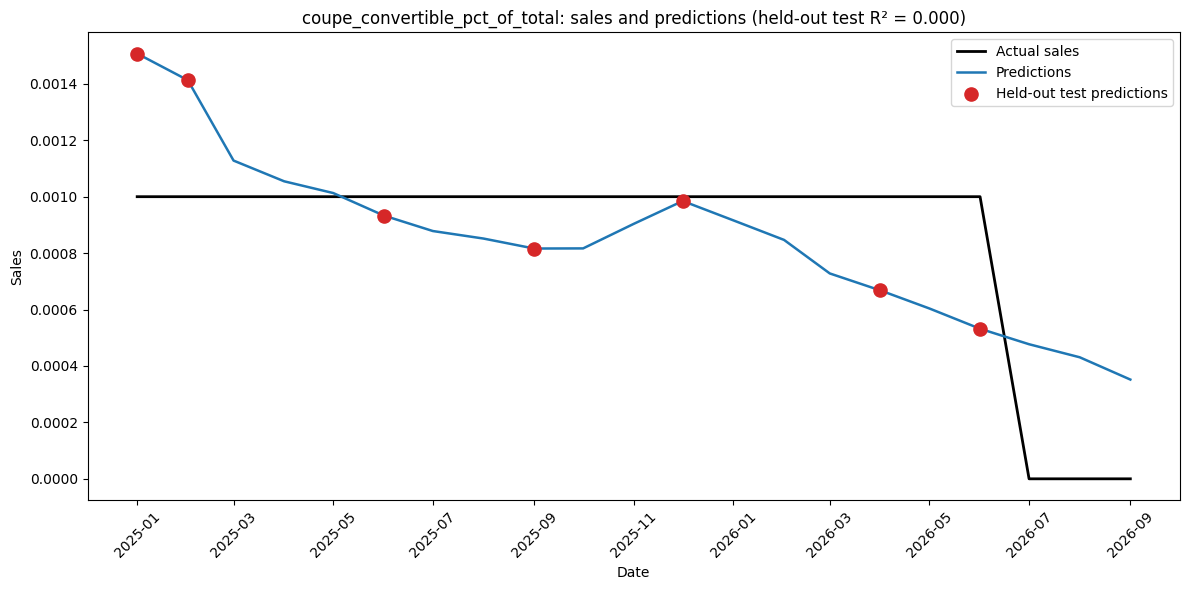

Saved results with model parameters to /home/lelandmesford/Projects/Predict_Car_Sales/best_parameters_2026-10-16.csv


(                             target  best_alpha     cv_r2  train_r2  \
 0                     suv_crossover         800  0.420871  0.647479   
 1                      pickup_truck         150  0.515522  0.871546   
 2                             sedan        1000  0.304134  0.621232   
 3                  mixed_body_style         700  0.412974  0.653926   
 4                           minivan         200 -0.260258  0.704195   
 5                    commercial_van         400  0.285271  0.722142   
 6                        sports_car        1400  0.146212  0.370339   
 7                hatchback_liftback         600  0.574489  0.760355   
 8                             wagon         400 -0.070561  0.629189   
 9                 coupe_convertible         500  0.546390  0.664046   
 10                       total_sold         600  0.518446  0.706573   
 11       suv_crossover_pct_of_total         400  0.312690  0.516866   
 12        pickup_truck_pct_of_total         700  0.287005  0.46

In [3]:
from pathlib import Path
from datetime import date
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGETS_PATH = Path('/home/lelandmesford/Projects/Predict_Car_Sales/car_sales_prediciton_targets.csv')
FEATURES_PATH = Path('/home/lelandmesford/Projects/Predict_Car_Sales/car_sales_prediction_features.csv')
ALPHAS = [1,10,30,50,70,90,150]+[100 * i for i in range(1, 31)]

targets = pd.read_csv(TARGETS_PATH)
features = pd.read_csv(FEATURES_PATH)

def find_date_column(frame, dataset_name):
    candidates = [c for c in frame.columns if 'date' in c.lower() or 'time' in c.lower()]
    if not candidates:
        raise ValueError(f'{dataset_name} has no identifiable date column.')
    parsed = {c: pd.to_datetime(frame[c], errors='coerce') for c in candidates}
    valid = [c for c, values in parsed.items() if values.notna().all()]
    if len(valid) != 1:
        raise ValueError(f'{dataset_name} has ambiguous or invalid date columns: {candidates}.')
    return valid[0]

target_date_column = find_date_column(targets, 'Targets dataset')
feature_date_column = find_date_column(features, 'Features dataset')
target_dates = pd.to_datetime(targets[target_date_column], errors='coerce')
feature_dates = pd.to_datetime(features[feature_date_column], errors='coerce')
if target_dates.isna().any():
    raise ValueError(f'Targets dataset contains unparseable dates in {target_date_column}: {targets.loc[target_dates.isna(), target_date_column].tolist()}')
if feature_dates.isna().any():
    raise ValueError(f'Features dataset contains unparseable dates in {feature_date_column}: {features.loc[feature_dates.isna(), feature_date_column].tolist()}')
if target_dates.duplicated().any():
    raise ValueError(f'Targets dataset contains duplicate dates: {target_dates[target_dates.duplicated()].tolist()}')
if feature_dates.duplicated().any():
    raise ValueError(f'Features dataset contains duplicate dates: {feature_dates[feature_dates.duplicated()].tolist()}')
if set(target_dates) != set(feature_dates):
    raise ValueError(f'Dataset dates differ. Only in targets: {sorted(set(target_dates) - set(feature_dates))}; only in features: {sorted(set(feature_dates) - set(target_dates))}')

targets = targets.copy()
features = features.copy()
targets['date'] = target_dates
features['date'] = feature_dates
if target_date_column != 'date':
    targets = targets.drop(columns=target_date_column)
if feature_date_column != 'date':
    features = features.drop(columns=feature_date_column)

merge_identifiers = sorted((set(targets.columns) & set(features.columns)) - {'date'})
target_columns = [c for c in targets.columns if c not in {'date', *merge_identifiers}]
feature_columns = [c for c in features.columns if c not in {'date', *merge_identifiers}]
if not target_columns or not feature_columns:
    raise ValueError('No target or feature columns remain after excluding dates and merge identifiers.')
merged = pd.merge(targets[['date', *target_columns]], features[['date', *feature_columns]], on='date', how='inner', validate='one_to_one', sort=False)
if len(merged) != len(targets) or len(merged) != len(features):
    raise ValueError('One-to-one date merge did not preserve every row from both datasets.')
if merged[feature_columns].isna().any().any() or merged[target_columns].isna().any().any():
    raise ValueError('Unexpected missing values found after merging; no imputation was requested.')

train_indices, test_indices = train_test_split(np.arange(len(merged)), test_size=0.30, train_size=0.70, random_state=RANDOM_STATE, shuffle=True)
X = merged[feature_columns]
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
results = []
models = {}
predictions = {}

for target in target_columns:
    y = merged[target]
    search = GridSearchCV(Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]), {'ridge__alpha': ALPHAS}, scoring='r2', cv=cv, refit=False)
    search.fit(X.iloc[train_indices], y.iloc[train_indices])
    best_alpha = search.best_params_['ridge__alpha']
    model = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=best_alpha))])
    model.fit(X.iloc[train_indices], y.iloc[train_indices])
    train_pred = model.predict(X.iloc[train_indices])
    test_pred = model.predict(X.iloc[test_indices])
    all_pred = np.full(len(merged), np.nan)
    all_pred[train_indices] = train_pred
    all_pred[test_indices] = test_pred
    models[target] = model
    predictions[target] = all_pred
    '''
    coefficients = model.named_steps['ridge'].coef_
    order = np.argsort(np.abs(coefficients))
    plt.figure(figsize=(10, max(6, len(feature_columns) * 0.16)))
    plt.barh(np.array(feature_columns)[order], coefficients[order], color='steelblue')
    plt.xlabel('Coefficient')
    plt.ylabel('Feature')
    plt.title(f'Standardized-feature coefficients: {target}\nAssociations, not causal importance')
    plt.axvline(0, color='black', linewidth=0.8)
    plt.tight_layout()
    plt.show()
    '''
    plot_data = merged[['date', target]].copy()
    plot_data['prediction'] = all_pred
    plot_data['is_test'] = False
    plot_data.loc[test_indices, 'is_test'] = True
    plot_data = plot_data.sort_values('date')
    test_plot_data = plot_data[plot_data['is_test']]
    test_r2 = r2_score(y.iloc[test_indices], test_pred)
    plt.figure(figsize=(12, 6))
    plt.plot(plot_data['date'], plot_data[target], label='Actual sales', color='black', linewidth=2)
    plt.plot(plot_data['date'], plot_data['prediction'], label='Predictions', color='tab:blue', linewidth=1.8)
    plt.scatter(test_plot_data['date'], test_plot_data['prediction'], label='Held-out test predictions', color='tab:red', s=90, zorder=3)
    plt.xlabel('Date')
    plt.ylabel('Sales')
    plt.title(f'{target}: sales and predictions (held-out test R² = {test_r2:.3f})')
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    best_parameters = {
        'transformation': {'class': 'StandardScaler', 'parameters': model.named_steps['scaler'].get_params()},
        'ridge': {'class': 'Ridge', 'parameters': model.named_steps['ridge'].get_params()},
        'k_fold': {'class': 'KFold', 'parameters': {'n_splits': cv.n_splits, 'shuffle': cv.shuffle, 'random_state': cv.random_state}},
        'train_test_split': {'test_size': 0.30, 'train_size': 0.70, 'shuffle': True, 'random_state': RANDOM_STATE},
        'grid_search': {'scoring': search.scoring, 'refit': search.refit, 'alpha_grid': ALPHAS},
    }
    flat_parameters = {
        **{f'ridge_{k}': v for k, v in best_parameters['ridge']['parameters'].items()},
        **{f'scaler_{k}': v for k, v in best_parameters['transformation']['parameters'].items()},
        **{f'kfold_{k}': v for k, v in best_parameters['k_fold']['parameters'].items()},
        **{f'split_{k}': v for k, v in best_parameters['train_test_split'].items()},
        'grid_scoring': search.scoring,
        'grid_refit': search.refit,
        'alpha_grid': json.dumps(ALPHAS),
        'random_state': RANDOM_STATE,
        'n_features': len(feature_columns),
        'n_train': len(train_indices),
        'n_test': len(test_indices),
    }
    train_mae = mean_absolute_error(y.iloc[train_indices], train_pred)
    test_mae = mean_absolute_error(y.iloc[test_indices], test_pred)
    train_mean = y.iloc[train_indices].mean()
    test_mean = y.iloc[test_indices].mean()
    results.append({'target': target, 'best_alpha': best_alpha, 'cv_r2': search.best_score_, 'train_r2': r2_score(y.iloc[train_indices], train_pred), 'test_r2': test_r2, 'train_mae': train_mae, 'test_mae': test_mae, 'target_mean_all': y.mean(), 'target_mean_train': train_mean, 'target_mean_test': test_mean, 'train_mae_pct_of_mean': 100 * train_mae / train_mean, 'test_mae_pct_of_mean': 100 * test_mae / test_mean, **flat_parameters, 'best_parameters': json.dumps(best_parameters, sort_keys=True)})

results_df = pd.DataFrame(results)
export_path = Path(f'/home/lelandmesford/Projects/Predict_Car_Sales/best_parameters_{date.today().isoformat()}.csv')
results_df.to_csv(export_path, index=False)
print(f'Saved results with model parameters to {export_path}')
randomness_df = pd.DataFrame([
    {'component': 'train_test_split', 'random_state': RANDOM_STATE, 'deterministic': True},
    {'component': 'KFold cross-validation', 'random_state': RANDOM_STATE, 'deterministic': True},
    {'component': 'StandardScaler', 'random_state': None, 'deterministic': True},
    {'component': 'Ridge', 'random_state': None, 'deterministic': True},
    {'component': 'GridSearchCV selection', 'random_state': None, 'deterministic': True},
])
results_df, randomness_df


In [4]:
results_df.to_csv('best_parameters_2026-10-15.csv',index=False)